#  9장. 자연어 전처리
## 9.1 자연어 처리란

우리가 일상생활에서 사용하는 언어 의미를 분석하여 컴퓨터가 처리할 수 있도록하는 과정이다.

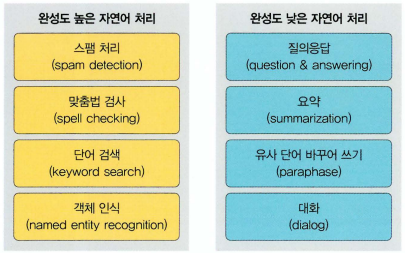



### 9.1.1 자연어 처리 용어 및 과정

**자연어 처리 관련 용어**

- 말뭉치(corpus): 자연어 처리에서 모델을 학습시키기 위한 데이터
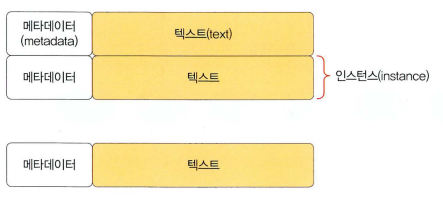

- 토큰(token): 문서를 나누는 단위
- 토큰화: 텍스트를 문장이나 단어로 분리하는 것
- 불용어(stop words): 문장 내에서 많이 등장하는 단어. 분석과 관계가 없으며, 자주 등장하는 빈도 때문에 성능에 영향이 가서 사전에 제거해야 함.
- 어간 추출(stemming): 단어를 기본 형태로 만드는 작업
- 품사 태깅(part of speech tagging): 주어진 문장에서 품사를 식별하기 위해 붙여 주는 태그
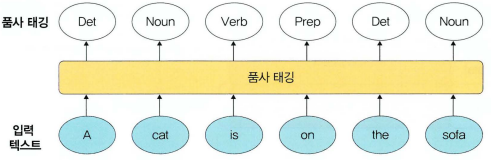

In [2]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

text = nltk.word_tokenize("IS it possible distinguishing cats and dogs")
text

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


['IS', 'it', 'possible', 'distinguishing', 'cats', 'and', 'dogs']

In [3]:
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [4]:
nltk.pos_tag(text)

[('IS', 'VBZ'),
 ('it', 'PRP'),
 ('possible', 'JJ'),
 ('distinguishing', 'VBG'),
 ('cats', 'NNS'),
 ('and', 'CC'),
 ('dogs', 'NNS')]

**자연어 처리 과정**  
자연어: 인간 언어  
1. 자연어가 입력 텍스트로 들어옴
2. 입력된 텍스트에 대한 전처리 과정
3. 전처리가 끝난 단어 임베딩
4. 모델을 이용하여 데이터에 대한 분류 및 예측 수행

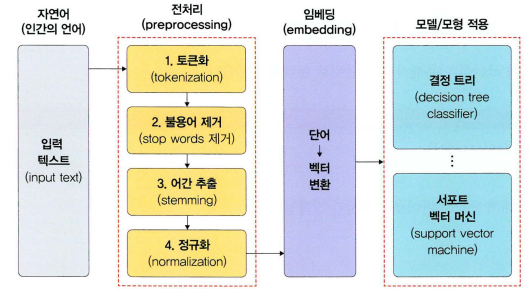

###9.1.2 자연어 처리를 위한 라이브러리
**NLTK**  
교육용으로 개발된 자연어 처리 및 문서 분석용 파이썬 라이브러리  
NLTK가 제공하는 주요 기능: **말뭉치, 토큰생성, 형태소 분석, 품사 태깅**

In [5]:
import nltk
nltk.download('punkt')
string1 = 'my favorite subject is math'
string2 = 'my favorite subject is math, english, economic and computer science'
nltk.word_tokenize(string1)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


['my', 'favorite', 'subject', 'is', 'math']

In [6]:
nltk.word_tokenize(string2)

['my',
 'favorite',
 'subject',
 'is',
 'math',
 ',',
 'english',
 ',',
 'economic',
 'and',
 'computer',
 'science']

**KoNLPy**  
한국어 처리를 위한 파이썬 라이브러리

In [7]:
# KoNLPy 작동을 위해 Java JDK 및 KoNLPy 패키지를 설치합니다.
!apt-get install -y openjdk-8-jdk-headless
!pip install konlpy

from konlpy.tag import Komoran
komoran = Komoran()
print(komoran.morphs('딥러닝이 쉽나요? 어렵나요?'))

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libxtst6 openjdk-8-jre-headless
Suggested packages:
  openjdk-8-demo openjdk-8-source libnss-mdns fonts-dejavu-extra fonts-nanum
  fonts-ipafont-gothic fonts-ipafont-mincho fonts-wqy-microhei
  fonts-wqy-zenhei fonts-indic
The following NEW packages will be installed:
  libxtst6 openjdk-8-jdk-headless openjdk-8-jre-headless
0 upgraded, 3 newly installed, 0 to remove and 0 not upgraded.
Need to get 39.6 MB of archives.
After this operation, 144 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libxtst6 amd64 2:1.2.3-1.1ubuntu0.1 [12.6 kB]
Ign:2 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 openjdk-8-jre-headless amd64 8u504-ga-1ubuntu1~24.04.3
Ign:3 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 openjdk-8-jdk-headless amd64 8u504-ga-1ubuntu1~24.04.3
Er

In [8]:
print(komoran.pos('소파 위에 있는 것이 고양이인가요? 강아지인가요?'))

[('소파', 'NNP'), ('위', 'NNG'), ('에', 'JKB'), ('있', 'VV'), ('는', 'ETM'), ('것', 'NNB'), ('이', 'JKS'), ('고양이', 'NNG'), ('이', 'VCP'), ('ㄴ가요', 'EF'), ('?', 'SF'), ('강아지', 'NNG'), ('이', 'VCP'), ('ㄴ가요', 'EF'), ('?', 'SF')]


**Gensim**

파이썬에서 제공하는 워드투벡터 라이브러리  
- 임베딩
- 토픽 모델링
- LDA(Latent Dirichlet Allocation)


**사이킷런**  
파이썬을 이용하여 문서를 전처리할 수 있는 라이브러리를 제공  
특성 추출 용도로 많이 사용
- CountVectorizer
- Tfidfvectorizer
- HashingVectorizer

# 13장. 생성모델

##13.1 생성 모델이란  
주어진 데이터를 학습하여 데이터 분포를 따르는 유사한 데이터를 생성하는 모델  

### 13.1.1 생성 모델 개념  
판별자 모델에서 추출한 특성들의 조합을 이용하여 새로운 개와 고양이 이미지를 생성할 수 있다.  

생성 모델은 입력 이미지에 대한 데이터 분포 $p(x)$를 학습하여 새로운 이미리를 생성하는 것을 목표로 한다.

###13.1.2 생성 모델의 유형

생성 모델의 유형에는 모델의 확률 변수를 구하는 '변형 오토인코더 모델'과 확률 변수를 이용하지 않는 'GAN 모델'이 있다.
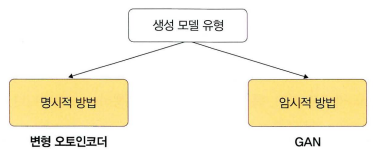

## 13.2 변형 오토인코더

### 13.2.1 오토인코더란?  
오토인코더는 단순히 입력을 출력으로 복사하는 신경망으로 은닉층의 노드 수가 입력 값보다 적은 것이 특징  
오토인코더의 주요 부분
1. 인코더: 특성에 대한 학습을 수행하는 부분
2. 병목층: 모델의 뉴런 개수가 최소인 계층
3. 디코더: 최대한 입력에 가까운 출력을 생성하도록 함
4. 손실 재구성

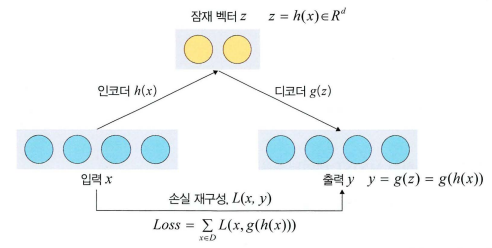

**오토인코더가 중요한 이유**
1. 데이터 압축
2. 차원의 저주
3. 특성 추출

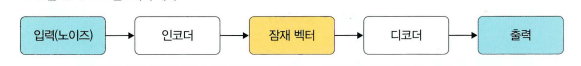

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

import torchvision.datasets as datasets
import torchvision.transforms as transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [10]:
!git clone https://github.com/gilbutITbook/080289.git

transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(root='./content/080289/chap13/data',
                               train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./content/080289/chap13/data',
                              train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=4, pin_memory=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)

fatal: destination path '080289' already exists and is not an empty directory.


100%|██████████| 9.91M/9.91M [00:00<00:00, 11.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 349kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.16MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.25MB/s]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [11]:
class Encoder(nn.Module):
  def __init__(self, encoded_space_dim, fc2_input_dim):
    super().__init__()

    self.encoder_cnn = nn.Sequential(
        nn.Conv2d(1, 8, 3, stride=2, padding=1),
        nn.ReLU(True),
        nn.Conv2d(8, 16, 3, stride=2, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Conv2d(16, 32, 3, stride=2, padding=0),
        nn.ReLU(True)
    )

    self.flatten = nn.Flatten(start_dim=1)
    self.encoder_lin = nn.Sequential(
        nn.Linear(3 * 3 * 32,128),
        nn.ReLU(True),
        nn.Linear(128, encoded_space_dim))

  def forward(self, x):
    x = self.encoder_cnn(x)
    x = self.flatten(x)
    x = self.encoder_lin(x)
    return x


class Decoder(nn.Module):
  def __init__(self, encoded_space_dim, fc2_input_dim):
    super().__init__()
    self.decoder_lin = nn.Sequential(
        nn.Linear(encoded_space_dim, 128),
        nn.ReLU(True),
        nn.Linear(128, 3 * 3 * 32),
        nn.ReLU(True)
    )

    self.unflatten = nn.Unflatten(dim=1, unflattened_size=(32, 3, 3))
    self.decoder_conv = nn.Sequential(
        nn.ConvTranspose2d(32,16,3,
                           stride=2, output_padding=0),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.ConvTranspose2d(16,8,3, stride=2,
                           padding=1, output_padding=1),
        nn.BatchNorm2d(8),
        nn.ReLU(True),
        nn.ConvTranspose2d(8,1,3,stride=2,
                           padding=1, output_padding=1)
        )


  def forward(self, x):
    x = self.decoder_lin(x)
    x = self.unflatten(x)
    x = self.decoder_conv(x)
    x = torch.sigmoid(x)
    return x

In [13]:
encoder = Encoder(encoded_space_dim=4, fc2_input_dim=128)
decoder = Decoder(encoded_space_dim=4, fc2_input_dim=128)
encoder.to(device)
decoder.to(device)

params_to_optimize = [
    {'params': encoder.parameters()},
    {'params': decoder.parameters()}
]

optim = torch.optim.Adam(params_to_optimize, lr=0.001, weight_decay=1e-05)
loss_fn = torch.nn.MSELoss()

오토인코더에서 가장 널리 사용되는 손실 함수는 **평균 제곱 오차**와 **이진 크로스 엔트로피**이다.

입력값이 (0,1) 범위에 있으면 이진 크로스 엔트로피를 사용  
그렇지 않으면 평균 제곱 오차를 사용

In [14]:
def train_epoch(encoder, decoder, device, dataloader, loss_fn, optimizer,
                noise_factor=0.3):
  encoder.train()
  decoder.train()
  train_loss=[]
  for image_batch, _ in dataloader:
    image_noisy = add_noise(image_batch + noise_factor)
    image_noisy = image_noisy.to(device)
    encoded_data = encoder(image_noisy)
    decoded_data = decoder(encoded_data)
    loss = loss_fn(decoded_data, image_noisy)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_loss.append(loss.detach().cpu().numpy())
  return np.mean(train_loss)

In [16]:
def test_epoch(encoder, decoder, device, dataloader, loss_fn, noise_factor=0.3):
  #Set evaluation mode for encoder and decoder
  encoder.eval()
  decoder.eval()
  with torch.no_grad():
    conc_out = []
    conc_label = []
    for image_batch, _ in dataloader:
        image_batch = image_batch.to(device)
        encoded_data = encoder(image_batch)
        decoded_data = decoder(encoded_data)
        conc_out.append(decoded_data.cpu())
        conc_label.append(image_batch.cpu())
    conc_out = torch.cat(conc_out)
    conc_label = torch.cat(conc_label)
    val_loss = loss_fn(conc_out, conc_label)
  return val_loss.data

In [17]:
def add_noise(inputs, noise_factor=0.3):
  noisy = inputs + torch.randn_like(inputs)*noise_factor
  noisy = torch.clip(noisy, 0.,1.)
  return noisy

In [18]:
#한글 깨짐 문제 해결

!apt-get -qq install fonts-nanum
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
font_family = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['font.family'] = font_family

Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


In [21]:
#이미지 시각화

def plot_ae_outputs(encoder, decoder, n=5, noise_factor=0.3):
  plt.figure(figsize=(10,4.5))
  for i in range(n):
    ax=plt.subplot(3, n, i+1)
    img=test_dataset[i][0].unsqueeze(0)
    image_noisy=add_noise(img, noise_factor)
    image_noisy = image_noisy.to(device)

    encoder.eval()
    decoder.eval()
    with torch.no_grad():
      rec_img = decoder(encoder(image_noisy))

    plt.imshow(img.cpu().squeeze().numpy(), cmap='gist_gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    if i == n//2:
      ax.set_title('노이즈가 적용되어 손상된 이미지')

    ax=plt.subplot(3, n, i+n+n)
    plt.imshow(image_noisy.cpu().squeeze().numpy(), cmap='gist_gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    if i == n//2:
      ax.set_title('재구성된 이미지')
  plt.subplots_adjust(left=0.1, bottom=0.1, right=0.7, top=0.9, wspace=0.3, hspace=0.3)
  plt.show()

EPOCH 1/30


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45432 (\N{HANGUL SYLLABLE NO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51592 (\N{HANGUL SYLLABLE JEU}) mis


 EPOCH 1/30 	 train loss 0.075 	 val loss 0.115


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51116 (\N{HANGUL SYLLABLE JAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


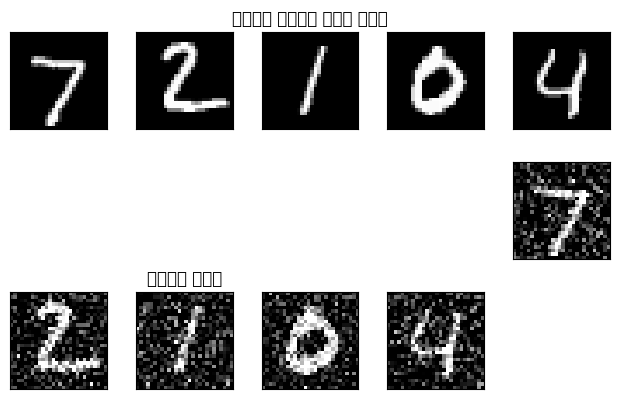

EPOCH 2/30



 EPOCH 2/30 	 train loss 0.074 	 val loss 0.114


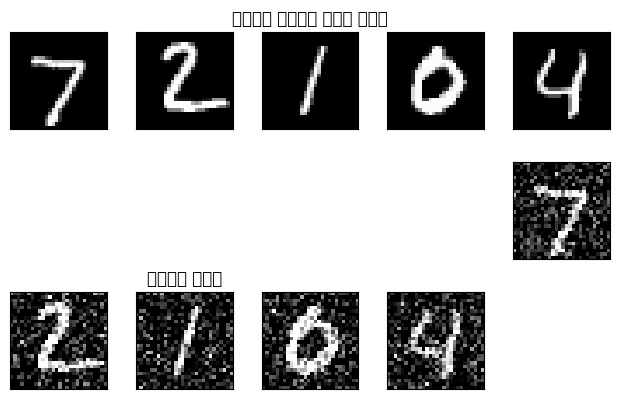

EPOCH 3/30



 EPOCH 3/30 	 train loss 0.074 	 val loss 0.114


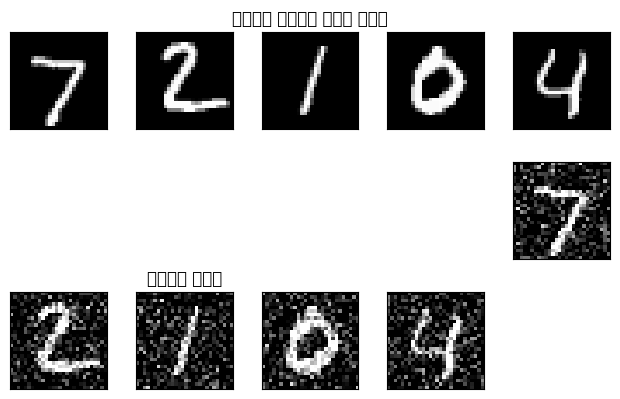

EPOCH 4/30



 EPOCH 4/30 	 train loss 0.073 	 val loss 0.113


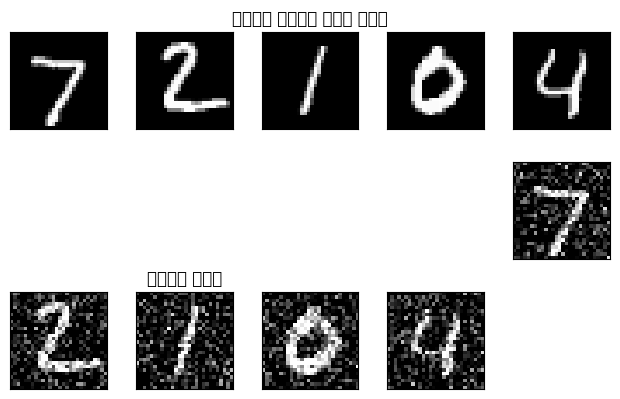

EPOCH 5/30



 EPOCH 5/30 	 train loss 0.073 	 val loss 0.113


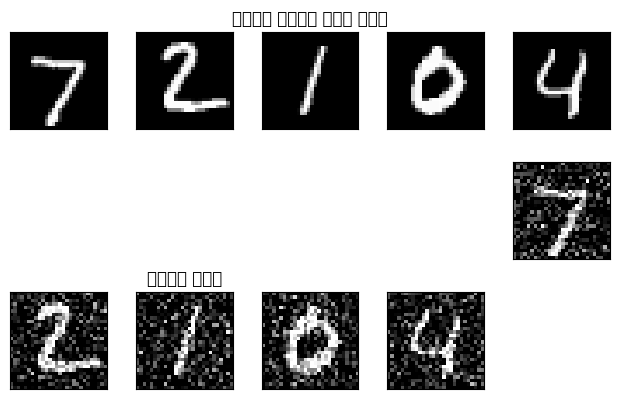

EPOCH 6/30



 EPOCH 6/30 	 train loss 0.073 	 val loss 0.112


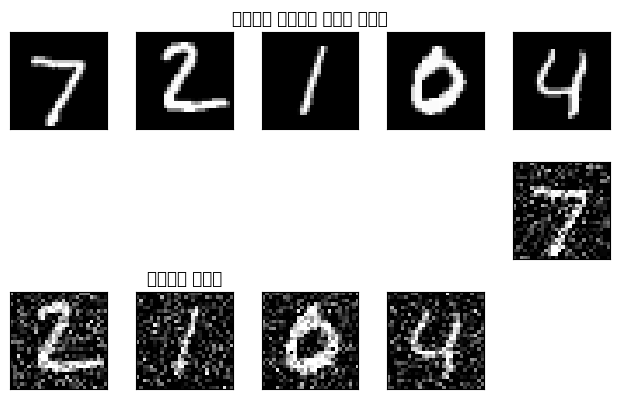

EPOCH 7/30

 EPOCH 7/30 	 train loss 0.073 	 val loss 0.114


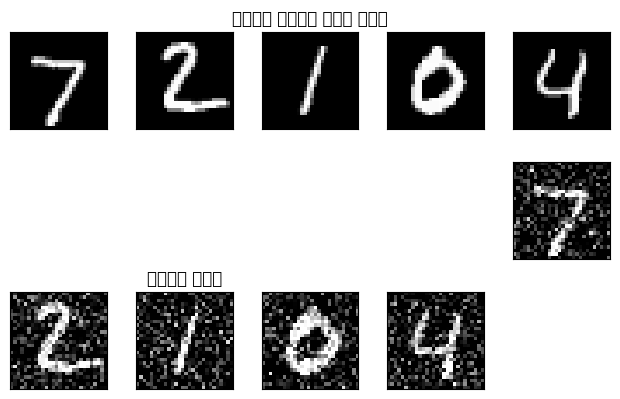

EPOCH 8/30



 EPOCH 8/30 	 train loss 0.073 	 val loss 0.113


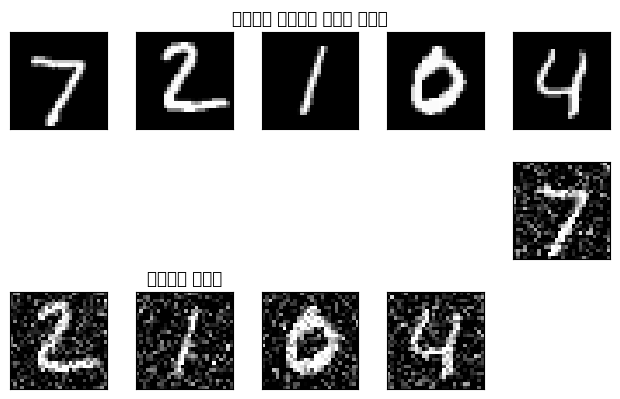

EPOCH 9/30



 EPOCH 9/30 	 train loss 0.072 	 val loss 0.112


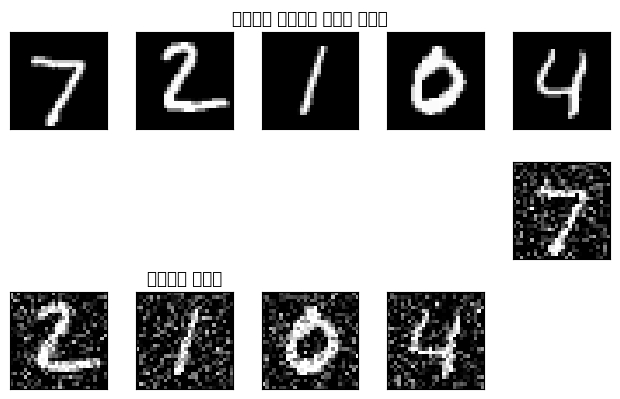

EPOCH 10/30



 EPOCH 10/30 	 train loss 0.072 	 val loss 0.113


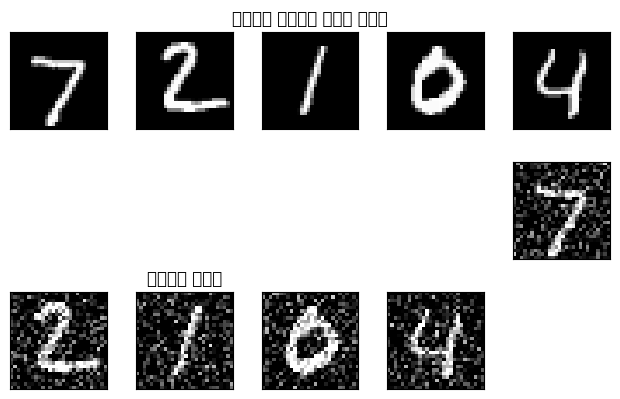

EPOCH 11/30



 EPOCH 11/30 	 train loss 0.072 	 val loss 0.112


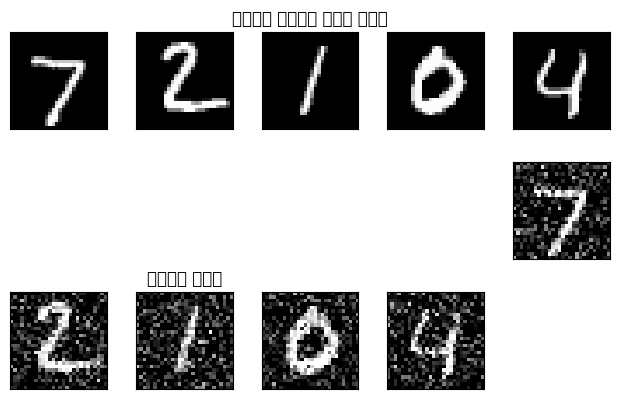

EPOCH 12/30



 EPOCH 12/30 	 train loss 0.072 	 val loss 0.113


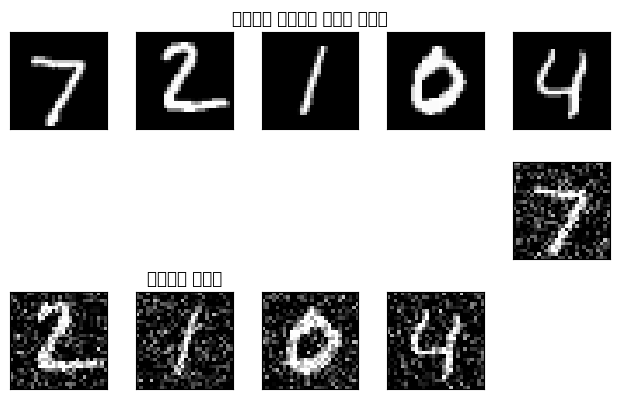

EPOCH 13/30



 EPOCH 13/30 	 train loss 0.072 	 val loss 0.112


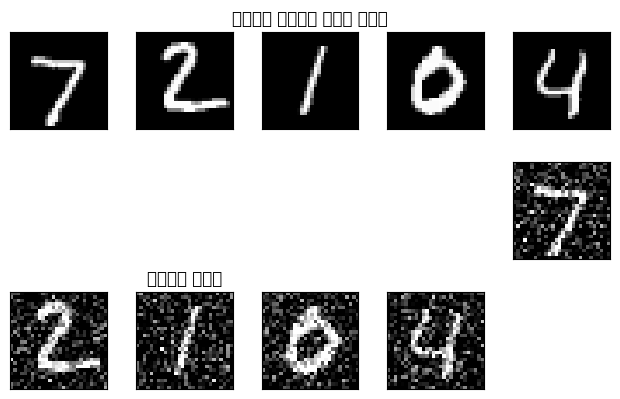

EPOCH 14/30

 EPOCH 14/30 	 train loss 0.072 	 val loss 0.112


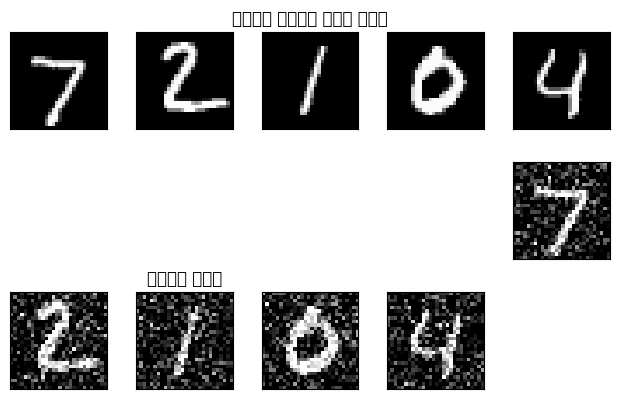

EPOCH 15/30



 EPOCH 15/30 	 train loss 0.072 	 val loss 0.113


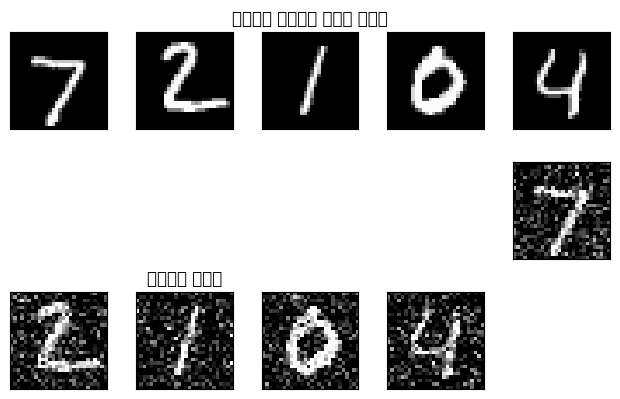

EPOCH 16/30



 EPOCH 16/30 	 train loss 0.072 	 val loss 0.112


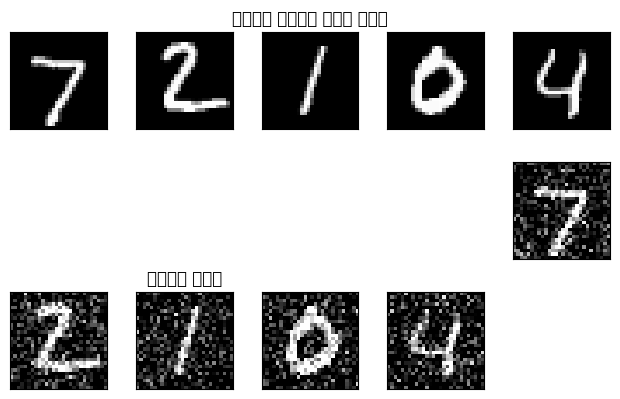

EPOCH 17/30



 EPOCH 17/30 	 train loss 0.072 	 val loss 0.111


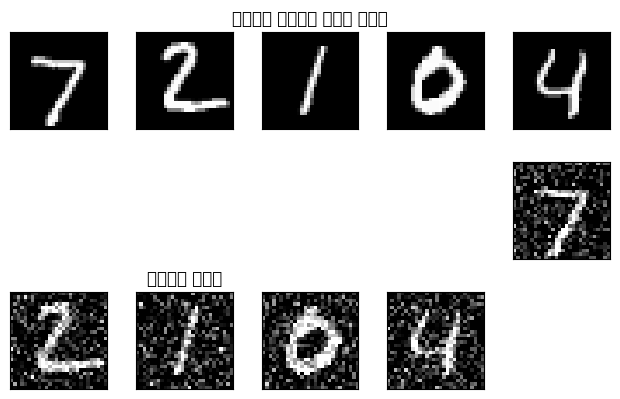

EPOCH 18/30



 EPOCH 18/30 	 train loss 0.072 	 val loss 0.113


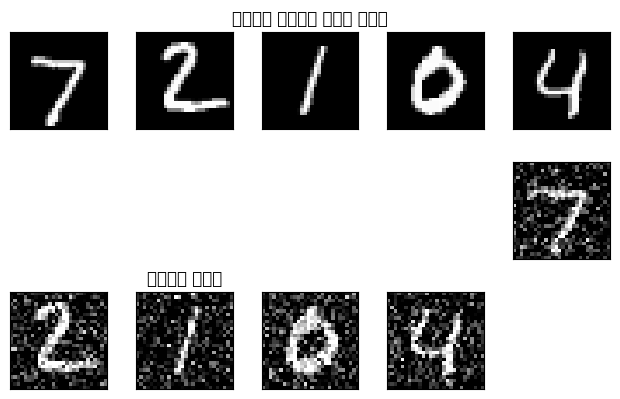

EPOCH 19/30



 EPOCH 19/30 	 train loss 0.072 	 val loss 0.114


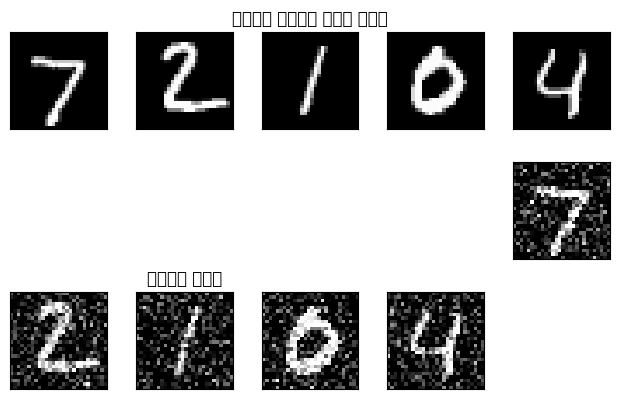

EPOCH 20/30



 EPOCH 20/30 	 train loss 0.072 	 val loss 0.112


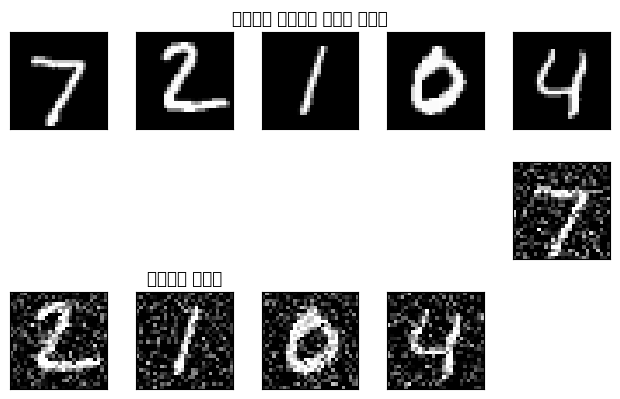

EPOCH 21/30



 EPOCH 21/30 	 train loss 0.072 	 val loss 0.112


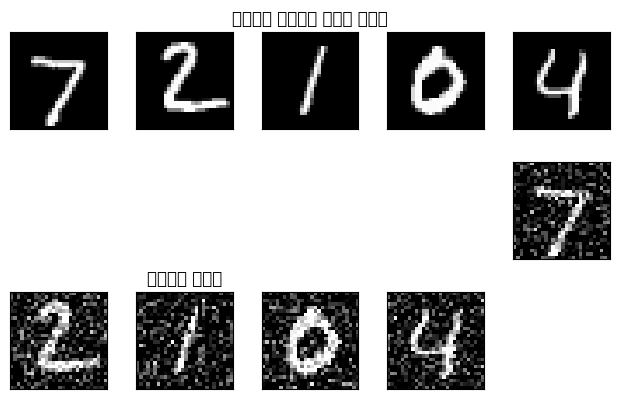

EPOCH 22/30



 EPOCH 22/30 	 train loss 0.072 	 val loss 0.112


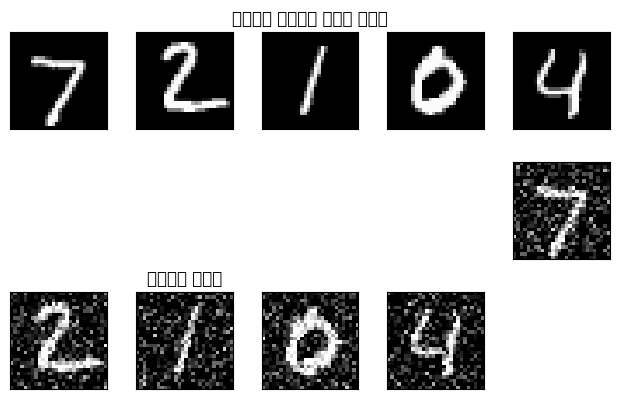

EPOCH 23/30



 EPOCH 23/30 	 train loss 0.072 	 val loss 0.113


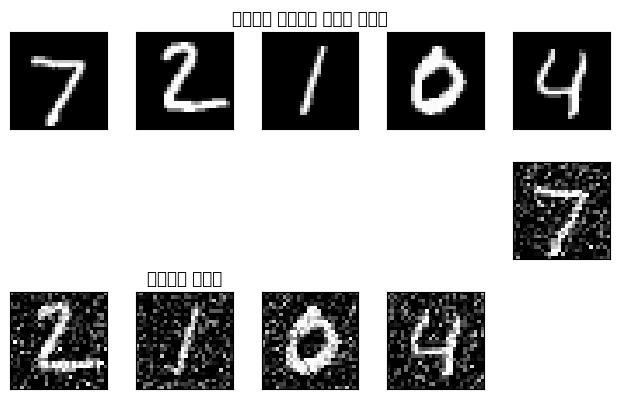

EPOCH 24/30



 EPOCH 24/30 	 train loss 0.072 	 val loss 0.111


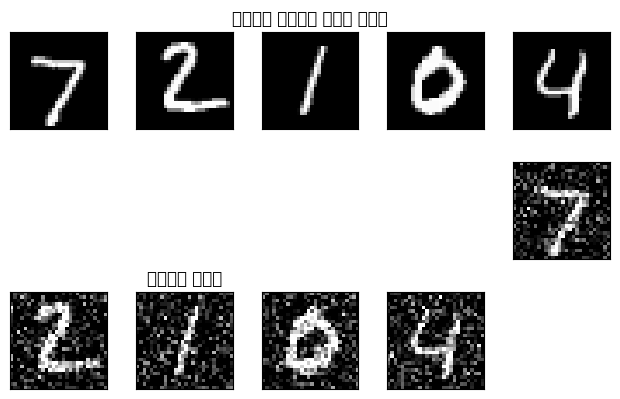

EPOCH 25/30



 EPOCH 25/30 	 train loss 0.072 	 val loss 0.112


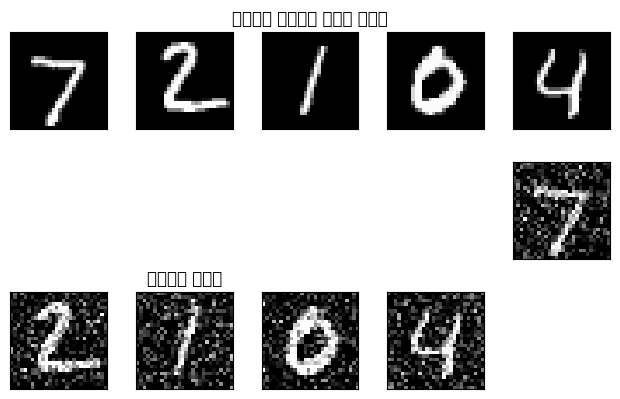

EPOCH 26/30



 EPOCH 26/30 	 train loss 0.072 	 val loss 0.113


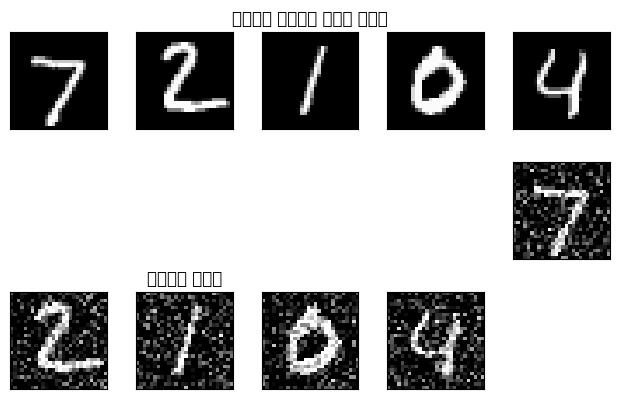

EPOCH 27/30



 EPOCH 27/30 	 train loss 0.072 	 val loss 0.111


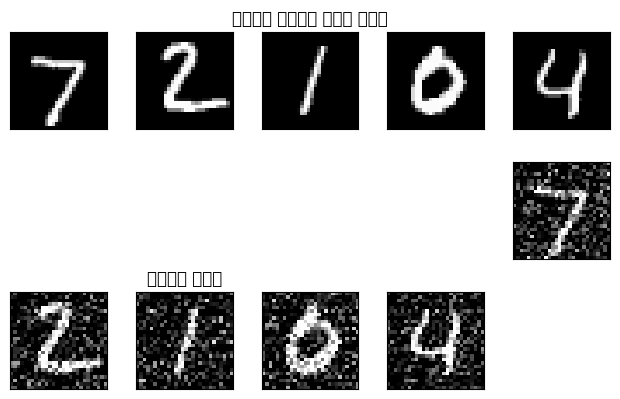

EPOCH 28/30



 EPOCH 28/30 	 train loss 0.072 	 val loss 0.112


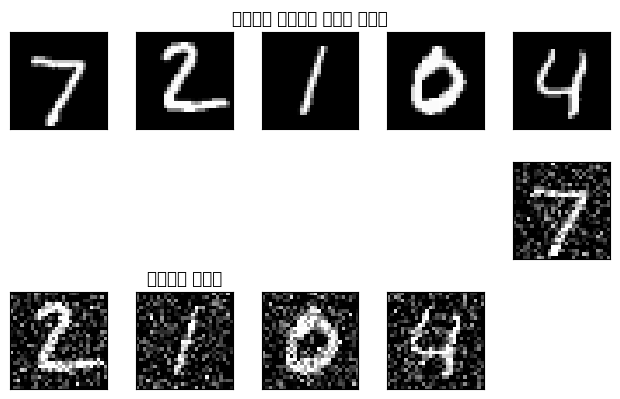

EPOCH 29/30



 EPOCH 29/30 	 train loss 0.072 	 val loss 0.111


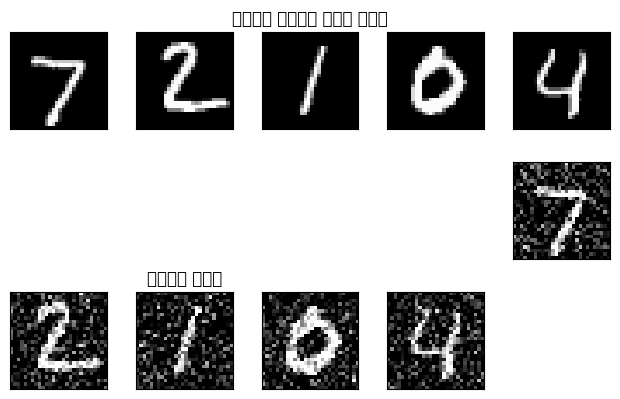

EPOCH 30/30



 EPOCH 30/30 	 train loss 0.072 	 val loss 0.111


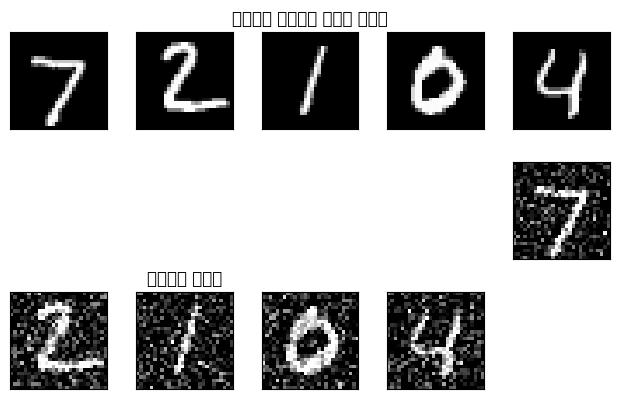

In [22]:
#모델 학습
import numpy as np

num_epochs = 30
history_da = {'train_loss':[],'val_loss':[]}
loss_fn = torch.nn.MSELoss()

for epoch in range(num_epochs):
  print('EPOCH %d/%d' % (epoch+1, num_epochs))
  train_loss = train_epoch(
      encoder = encoder,
      decoder = decoder,
      device = device,
      dataloader = train_loader,
      loss_fn = loss_fn,
      optimizer = optim, noise_factor=0.3)
  val_loss = test_epoch(
      encoder = encoder,
      decoder = decoder,
      device = device,
      dataloader = test_loader,
      loss_fn = loss_fn, noise_factor=0.3)
  history_da['train_loss'].append(train_loss)
  history_da['val_loss'].append(val_loss)
  print('\n EPOCH {}/{} \t train loss {:.3f} \t val loss {:.3f}'.format(epoch+1,
                                                                        num_epochs, train_loss, val_loss))
  plot_ae_outputs(encoder, decoder, noise_factor=0.3)

###13.2.2 변형 오토인코더

표준편차와 평균을 이용하여 확률 분포를 만들고, 거기에서 샘플링하여 디코더를 통과시킨 후 새로운 데이터를 만들어 낸다.  
즉, 변형 오토인코더는 입력 데이터와 조금 다른 출력 데이터를 만들어 내는데, 이때 z라는 가우시안 분포를 이용한다.  
중요한 특성의 파라미터를 담고있는 z분포에서 벡터를 랜덤하게 샘플링하고 이 분포의 오차를 이용하여 입력 데이터와 유사한 다양한 데이터를 만들어 내는 것이 변형 오토인코더이다.

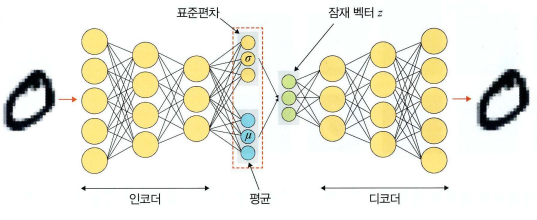

In [25]:
!pip install tensorboardX

import datetime
import os
from tensorboardX import SummaryWriter

import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pylab as plt

import torchvision.datasets as datasets
import torchvision.transforms as transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

MNIST 데이터셋을 내려받은 후 이미지를 텐서로 변환

In [39]:
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(
    root='./content/080289/chap13/data', train=True, download=True, transform=transform)

test_dataset = datasets.MNIST(
    root='./content/080289/chap13/data', train=False, download=True, transform=transform)

train_loader = DataLoader(
    train_dataset, batch_size=100, shuffle=True, num_workers=4, pin_memory=False)

test_loader = DataLoader(
    test_dataset, batch_size=100, shuffle=False, num_workers=4)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [40]:
#인코더 네트워크 생성
class Encoder(nn.Module):
  def __init__(self, input_dim, hidden_dim, latent_dim):
    super(Encoder, self).__init__()
    self.input1 = nn.Linear(input_dim, hidden_dim)
    self.input2 = nn.Linear(hidden_dim, hidden_dim)
    self.mean = nn.Linear(hidden_dim, latent_dim)
    self.var = nn.Linear(hidden_dim, latent_dim)

    self.LeakyReLU = nn.LeakyReLU(0.2)
    self.training = True

  def forward(self, x):
    h_ = self.LeakyReLU(self.input1(x))
    h_ = self.LeakyReLU(self.input2(h_))
    mean = self.mean(h_)
    log_var = self.var(h_)
    return mean, log_var

In [41]:
#디코더 네트워크
class Decoder(nn.Module):
  def __init__(self, latent_dim, hidden_dim, output_dim):
    super(Decoder, self).__init__()
    self.hidden1 = nn.Linear(latent_dim, hidden_dim)
    self.hidden2 = nn.Linear(hidden_dim, hidden_dim)
    self.output = nn.Linear(hidden_dim, output_dim)
    self.LeakyReLU = nn.LeakyReLU(0.2)

  def forward(self, x):
    h = self.LeakyReLU(self.hidden1(x))
    h = self.LeakyReLU(self.hidden2(h))
    x_hat = torch.sigmoid(self.output(h))
    return x_hat

In [42]:
class Model(nn.Module):
  def __init__(self, Encoder, Decoder):
    super(Model, self).__init__()
    self.Encoder = Encoder
    self.Decoder = Decoder

  def reparameterization(self, mean, var):
    epsilon = torch.randn_like(var).to(device)
    z = mean + var * epsilon
    return z

  def forward(self, x):
    mean, log_var = self.Encoder(x)
    z = self.reparameterization(mean, torch.exp(0.5 * log_var))
    x_hat = self.Decoder(z)
    return x_hat, mean, log_var

In [43]:
#인코더와 디코더 객체 초기화
x_dim = 784
hidden_dim = 400
latent_dim = 200
epochs = 30
batch_size = 100

encoder = Encoder(input_dim=x_dim, hidden_dim=hidden_dim, latent_dim=latent_dim)
decoder = Decoder(latent_dim=latent_dim, hidden_dim=hidden_dim, output_dim=x_dim)

model = Model(Encoder=encoder, Decoder=decoder).to(device)

In [44]:
#손실 함수 정의
def loss_function(x, x_hat, mean, log_var):
  reproduction_loss = nn.functional.binary_cross_entropy(x_hat, x, reduction='sum')
  KLD = -0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp())
  return reproduction_loss, KLD


optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [45]:
#모델 학습 함수 정의
saved_loc = 'scalar/'
writer = SummaryWriter(saved_loc)

model.train()
def train(epoch, model, train_loader, optimizer):
  train_loss = 0
  for batch_idx,(x,_) in enumerate(train_loader):
    x = x.view(batch_size, x_dim)
    x = x.to(device)

    optimizer.zero_grad()
    x_hat, mean, log_var = model(x)
    BCE, KLD = loss_function(x, x_hat, mean, log_var)
    loss = BCE + KLD
    writer.add_scalar('Train/Reconstruction Error', BCE.item(), batch_idx+epoch*(len(train_loader.dataset)/batch_size))
    writer.add_scalar('Train/KL-Divergence', KLD.item(), batch_idx+epoch*(len(train_loader.dataset)/batch_size))
    writer.add_scalar('Train/Total Loss', loss.item(), batch_idx+epoch*(len(train_loader.dataset)/batch_size))

    train_loss += loss.item()
    loss.backward()
    optimizer.step()

    if batch_idx % 100 ==0:
      print('Train Epoch: {}[{}/{} ({:.0f}%)]\t Loss: {:.6f}'.format(
          epoch, batch_idx * len(x), len(train_loader.dataset),
          100. * batch_idx / len(train_loader), loss.item() / len(x)))

  print('======> Epoch: {} Average loss: {:.4f}'.format(
      epoch, train_loss / len(train_loader.dataset)))

In [51]:
#모델 평가 함수 정의
def test(epoch, model, test_loader):
  model.eval()
  test_loss = 0
  with torch.no_grad():
    for batch_idx, (x, _) in enumerate(test_loader):
      x = x.view(batch_size, x_dim)
      x = x.to(device)
      x_hat, mean, log_var = model(x)
      BCE, KLD = loss_function(x, x_hat, mean, log_var)
      loss = BCE + KLD

      writer.add_scalar('Test/Reconstruction Error', BCE.item(), batch_idx+epoch*(len(test_loader.dataset)/batch_size))
      writer.add_scalar('Test/KL-Divergence', KLD.item(), batch_idx+epoch*(len(test_loader.dataset)/batch_size))
      writer.add_scalar('Test/Total Loss', loss.item(), batch_idx+epoch*(len(test_loader.dataset)/batch_size))

      test_loss += loss.item()

      if batch_idx == 0:
        n = min(x.size(0), 8)
        comparision = torch.cat([x[:n].view(-1, 1, 28, 28), x_hat.view(-1, 1, 28, 28)[:n]])
        grid = torchvision.utils.make_grid(comparision.cpu())
        writer.add_image('Test image - Above: Real data, below: reconstruction data', grid, epoch)

In [52]:
from tqdm import tqdm
for epoch in tqdm(range(0, epochs)):
  train(epoch, model, train_loader, optimizer)
  test(epoch, model, test_loader)
  print('\n')
writer.close()

  0%|          | 0/30 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Train Epoch: 0[0/60000 (0%)]	 Loss: 121.806826
Train Epoch: 0[10000/60000 (17%)]	 Loss: 120.851299
Train Epoch: 0[20000/60000 (33%)]	 Loss: 119.678555
Train Epoch: 0[30000/60000 (50%)]	 Loss: 120.976768
Train Epoch: 0[40000/60000 (67%)]	 Loss: 118.752617
Train Epoch: 0[50000/60000 (83%)]	 Loss: 113.415674
======> Epoch: 0 Average loss: 117.1212


  3%|▎         | 1/30 [00:27<13:18, 27.55s/it]



Train Epoch: 1[0/60000 (0%)]	 Loss: 109.342832
Train Epoch: 1[10000/60000 (17%)]	 Loss: 110.895771
Train Epoch: 1[20000/60000 (33%)]	 Loss: 118.079219
Train Epoch: 1[30000/60000 (50%)]	 Loss: 108.306758
Train Epoch: 1[40000/60000 (67%)]	 Loss: 116.209170
Train Epoch: 1[50000/60000 (83%)]	 Loss: 110.239746
======> Epoch: 1 Average loss: 112.2082


  7%|▋         | 2/30 [00:54<12:45, 27.32s/it]



Train Epoch: 2[0/60000 (0%)]	 Loss: 105.003125
Train Epoch: 2[10000/60000 (17%)]	 Loss: 112.307207
Train Epoch: 2[20000/60000 (33%)]	 Loss: 108.219590
Train Epoch: 2[30000/60000 (50%)]	 Loss: 109.489482
Train Epoch: 2[40000/60000 (67%)]	 Loss: 107.419951
Train Epoch: 2[50000/60000 (83%)]	 Loss: 108.648281
======> Epoch: 2 Average loss: 109.7635


... (51 outputs left out)



Train Epoch: 28[0/60000 (0%)]	 Loss: 104.411172
Train Epoch: 28[10000/60000 (17%)]	 Loss: 99.881035
Train Epoch: 28[20000/60000 (33%)]	 Loss: 103.151855
Train Epoch: 28[30000/60000 (50%)]	 Loss: 98.612754
Train Epoch: 28[40000/60000 (67%)]	 Loss: 102.365293
Train Epoch: 28[50000/60000 (83%)]	 Loss: 99.126787
======> Epoch: 28 Average loss: 100.2076


 97%|█████████▋| 29/30 [13:03<00:27, 27.04s/it]



Train Epoch: 29[0/60000 (0%)]	 Loss: 99.409766
Train Epoch: 29[10000/60000 (17%)]	 Loss: 102.754990
Train Epoch: 29[20000/60000 (33%)]	 Loss: 102.559355
Train Epoch: 29[30000/60000 (50%)]	 Loss: 99.721621
Train Epoch: 29[40000/60000 (67%)]	 Loss: 102.905566
Train Epoch: 29[50000/60000 (83%)]	 Loss: 95.442451
======> Epoch: 29 Average loss: 100.0843


100%|██████████| 30/30 [13:30<00:00, 27.02s/it]

In [53]:
#텐서보드에서 오차 확인

%load_ext tensorboard
%tensorboard --logdir scalar --port=6013

<IPython.core.display.Javascript object>